<a href="https://colab.research.google.com/github/porygon-tech/chemostat/blob/main/METAB4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/porygon-tech/chemostat
%cd /content/chemostat
!git pull

fatal: destination path 'chemostat' already exists and is not an empty directory.
/content/chemostat
Already up to date.


In [2]:
import importlib
import chii.tools
import chii.aux

importlib.reload(chii.tools)
importlib.reload(chii.aux)

<module 'chii.aux' from '/content/chemostat/chii/aux.py'>

In [3]:
%%capture
!pip install pyfish

In [4]:
import sys
sys.path.insert(0, '/content/chemostat')

In [5]:
from chii.tools import *
from chii.aux import *

# Quadrant invasions

In a two-resident setup, simulate many mutants and measure % cases the mutant falls in the superbug category. Repeat this for other scenarios with varying levels of distance between both residents'eta ratios and see if this distance changes consistently the % of superbugs.

In [29]:
#@markdown helper function for this test
def test_quadrant_invasions(pars, k=500, seed=None, pllim = 1.2,plot = True):
    # k: times to mutate each resident
    ps_tmp=deepcopy(pars)
    M,S,D,U,T,L,Fn,Ft,Phi,psi,f_n,f_t,_ = ps_tmp.values()
    eta_lock = Fn/(U*d_AR/d_dd-1)
    cstar_OG, _,_,_ = get_c_p_m_star2(ps_tmp)
    # mutate
    rng = gen_rng(seed=seed, verbose=True)

    for parent in (0,1):
        mEffs = formatted_mutEffs(ps_tmp['M'], U_corr, T_corr, U_vars, T_vars, single_molec, single_sector, single_param, rng, nsamples=k) # create mutation effects
        introduce_several_mutants(ps_tmp, parent, mEffs) # much faster
    # lambda_mut = (get_growth_rates(ps_tmp, X0)).max(0)

    #
    cstar, p_star, mstar, a_star, eta = get_c_p_m_star2(ps_tmp,get_cMiki=True)
    if plot:

        fig, ax = plt.subplots(figsize=(7,7))
        ax.scatter(*eta,s=.5)
        ax.scatter(*eta_lock)
        ax.scatter(*cstar_OG)
        # plt.scatter(*cstar)
        # ax = plt.gca()
        axxlim = ax.get_xlim()

        x_vals2 = np.linspace(0, pllim, 200)
        regimeCurves = -(U[0,:]*Fn[1,:]*np.c_[x_vals2]) / (U[0,:]*np.c_[x_vals2] - U[1,:]*(Fn[0,:] + np.c_[x_vals2]))
        ax.plot(x_vals2, regimeCurves,linewidth=.3)


        #--------------------
        x, y = eta[:,:2]
        # x, y = eta

        ax.scatter(x, y, s=.5)
        ax.vlines(x, 0, y, linewidth=.5,linestyle='--')
        ax.hlines(y, 0, x, linewidth=.5,linestyle='--')

        #--------------------

        ax.set_aspect('equal')


        ax.set_xlim(0,pllim)
        ax.set_ylim(0,pllim)
        plt.show()

    # is_superbug = (eta<cstar_OG[:,None]).all(axis=0)
    is_superbug = (eta<cstar_OG[:,None]).all(axis=0)
    print(f'{is_superbug.sum()}/{eta.shape[1]-2} superbugs')
    return ps_tmp, is_superbug

In [18]:
#@markdown Create residents

seed= 375 #array([147, 168, 183, 197, 208, 251, 264, 268, 345, 388, 389, 400, 440, 469, 542, 545, 548, 557, 617, 641, 691, 708, 722, 724, 764, 775, 798, 804, 807, 814, 901, 923, 972, 974])
M=2
S=2
V =1e15 # 1 Liter
cP=3e6

params, (X0,Y0,m0,P0,R0) = create_residents(seed, M, S, V, cP)
M,S,D,U,T,L,Fn,Ft,Phi,psi,f_n,f_t,_ = params.values()
cstar, p_star, mstar, a_star, eta = get_c_p_m_star2(params,get_cMiki=True)

print(np.all(cstar[:,I]<eta,axis=0)) # this tells whether it is really not viable. Any True will mean species is not viable
print(mstar) # IN CASE of being viable, this is the population size reached

#======== forced alterations ===============
# params['U' ][:,0]=params['U' ][:,1]
# params['Fn'][:,0]=params['Fn'][:,1]
params['U' ][:,0]=params['U' ][::-1,1]
params['Fn'][:,0]=params['Fn'][::-1,1]
params['L'] *=1.5 #!!!!!!!!!!
params['L'] [  1]=params['L' ][0]
params['T' ][  0]=params['T' ][1]

params['U' ][0,1]/=.5
params['U' ][1,0]/=.5
params['T' ]*=0.7

M,S,D,U,T,L,Fn,Ft,Phi,psi,f_n,f_t,_ = params.values()
cstar, p_star, mstar, a_star, eta = get_c_p_m_star2(params,get_cMiki=True)

print(np.all(cstar[:,I]<eta,axis=0)) # this tells whether it is really not viable. Any True will mean species is not viable
print(mstar) # IN CASE of being viable, this is the population size reached


seed: 375
[ True False]
[[2.24675183e-08]
 [2.07528014e-03]]
[False False]
[[0.00051616]
 [0.00051616]]


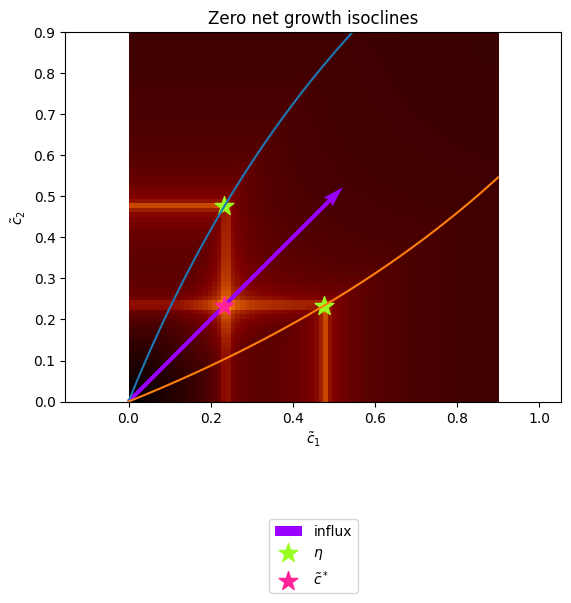

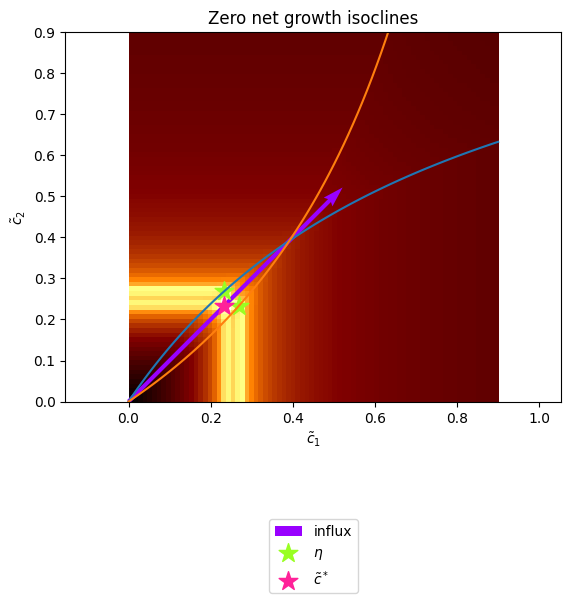

In [19]:
#@markdown Create a copy changing inactive $\eta$ coordinates (fixed ss concentrations)
from copy import deepcopy
params2 = deepcopy(params)
factor = 0.6

params2['U' ][0,0]#*=factor
params2['U' ][0,1]/=factor
params2['U' ][1,0]/=factor
params2['U' ][1,1]#*=factor

# params2['Fn'][:,0]/=factor
# params2['Fn'][:,1]*=factor
aux_plot_ZNGIs(params)
aux_plot_ZNGIs(params2)

In [20]:
#@markdown Mutator setup
seed = 190 #np.random.randint(10) # None for random seed. 644 897 894
U_corr=0. # covariance between mutation effects on Kcat and halfsat in uptake transporters
T_corr=0. # covariance between mutation effects on Kcat and halfsat in ribosomes
U_vars= np.array([3e-3,0e-4]) # mutation effect variances in Kcat, F for uptakers
T_vars= np.array([3e-2,0e-4]) # mutation effect variances in Kcat, F for ribosomes
ntries=20 # max number of times tried to get all positive mutants (DEP)
extinctAfter = True # remove the strain that should go extinct from the matrix
mutation_rounds = 2000 # times to mutate population
single_molec=True
single_sector=True
single_param=True
smoothChoice=True
popthres=8e-12

seed: 721


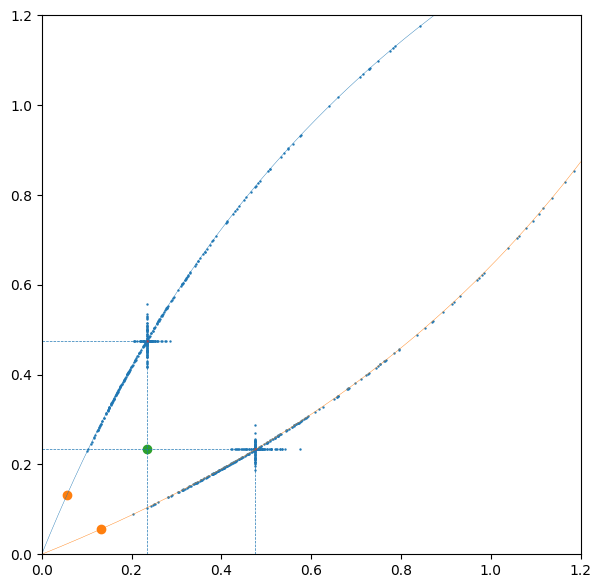

19/1000 superbugs
seed: 562


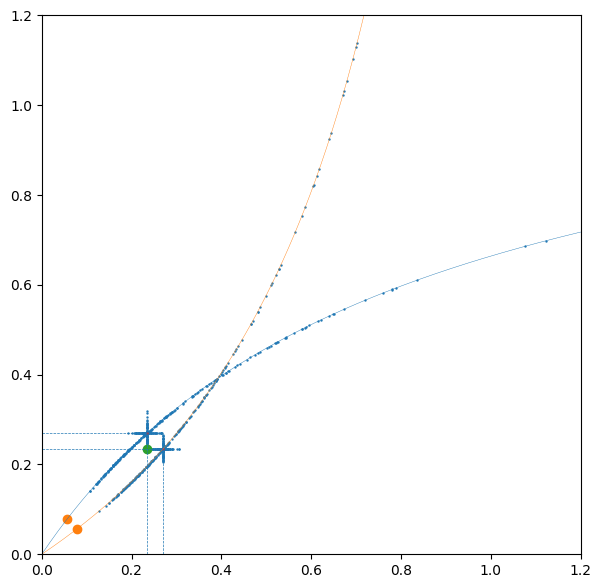

178/1000 superbugs


In [24]:
case1, is_superbug1 = test_quadrant_invasions(params )
case2, is_superbug2 = test_quadrant_invasions(params2)

In [34]:
n_sb = []
factor_list = np.linspace(0.95,0.5,35)
k=600
for factor in factor_list:
    params2 = deepcopy(params)
    params2['U' ][0,1]/=factor
    params2['U' ][1,0]/=factor
    case2, is_superbug2 = test_quadrant_invasions(params2,plot=False)
    n_sb.append(is_superbug2.sum()/k*2)

seed: 977


/content/chemostat/chii/tools.py:367: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-a*d))


13/1000 superbugs
seed: 333
21/1000 superbugs
seed: 751
15/1000 superbugs
seed: 762
18/1000 superbugs
seed: 668
22/1000 superbugs
seed: 69
24/1000 superbugs
seed: 474
24/1000 superbugs
seed: 979
29/1000 superbugs
seed: 859
24/1000 superbugs
seed: 14
34/1000 superbugs
seed: 346
42/1000 superbugs
seed: 106
37/1000 superbugs
seed: 122
39/1000 superbugs
seed: 755
49/1000 superbugs
seed: 56
66/1000 superbugs
seed: 877
62/1000 superbugs
seed: 379
79/1000 superbugs
seed: 848
82/1000 superbugs
seed: 528
119/1000 superbugs
seed: 833
85/1000 superbugs
seed: 565
101/1000 superbugs
seed: 928
114/1000 superbugs
seed: 880
133/1000 superbugs
seed: 836
145/1000 superbugs
seed: 750
146/1000 superbugs
seed: 625
162/1000 superbugs
seed: 527
191/1000 superbugs
seed: 908
178/1000 superbugs
seed: 587
192/1000 superbugs
seed: 296
204/1000 superbugs
seed: 961
205/1000 superbugs
seed: 168
247/1000 superbugs
seed: 644
254/1000 superbugs
seed: 799
227/1000 superbugs
seed: 8
219/1000 superbugs


Text(0, 0.5, 'superbugs/total mutants')

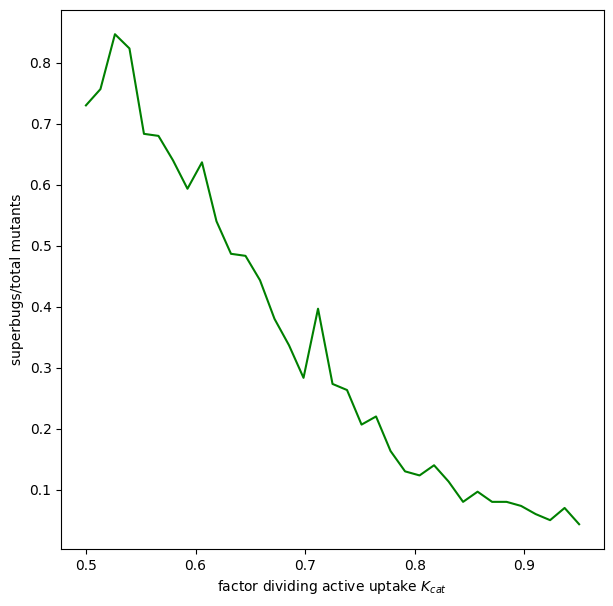

In [37]:
#@title Result
#@markdown % superbug mutants decays with distance of inactive $\eta$ (~unused uptake flux) from the ss concentrations.
fig, ax = plt.subplots(figsize=(7,7))
ax.plot(factor_list, n_sb,color='green')
ax.set_xlabel(r'factor dividing active uptake $K_{cat}$')
ax.set_ylabel(r'superbugs/total mutants')